# Diabetic Retinopathy Detection

## Business Case
Retinopathy is damage or disease of the retina — the light-sensitive tissue at the back of the eye responsible for vision. It is commonly linked to diabetes and high blood pressure, and can lead to vision loss or blindness if not detected early.

## Project Goal
Create a model that can detect the type (severity category) of diabetic retinopathy present in a retina scan image, using the provided dataset.

## Dataset
- Source: Client-provided dataset (`ratinopathy`)
- Structure: a `.csv` file mapping image filename → encoded category, plus an images directory
- Exact folder layout, image count, and number of classes to be confirmed in Section 1 below

## Approach
- Explore dataset structure and class distribution
- Clean and preprocess images
- Apply transfer learning (pretrained CNN backbone) with a custom classification head
- Use data augmentation and early stopping to control overfitting
- Evaluate with confusion matrix and classification report
- Interpret predictions visually (Grad-CAM) to show which part of the retina drove each prediction

## 1. Import Libraries & Load Dataset

In [1]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.models import Model
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import os
import warnings
warnings.filterwarnings("ignore")

In [2]:
data_dir = os.path.join("..", "data", "ratinopathy")  # see data/README.md
print("Path exists:", os.path.exists(data_dir))

Path exists: True


In [3]:
for root, dirs, files in os.walk(data_dir):
    level = root.replace(data_dir, "").count(os.sep)
    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")
    if files:
        # show a couple of sample filenames, not all, to keep output readable
        sample = files[:3]
        print(f"{indent}  -> {len(files)} files, e.g. {sample}")

ratinopathy/
  -> 1 files, e.g. ['data_all.csv']
  images/
    -> 1764 files, e.g. ['o_c1t10003118.jpg', 'o_c1t1003016260.jpg', 'o_c1t1004522299.jpg']


## 2. Load and Inspect Labels

In [4]:
csv_path = os.path.join(data_dir, "data_all.csv")
df = pd.read_csv(csv_path)
print("Shape:", df.shape)
df.head()

Shape: (1764, 3)


,Unnamed: 0,file,cat
0,0,o_c1t10003118.jpg,1
1,1,o_c1t1003016260.jpg,1
2,2,o_c1t1004522299.jpg,1
3,3,o_c1t1008823172.jpg,1
4,4,o_c1t1011431188.jpg,1


In [5]:
print("Columns:", df.columns.tolist())
print()
print(df.dtypes)
print()
# assuming the label is the last column — adjust once we see real column names
label_col = df.columns[-1]
print(f"Value counts for '{label_col}':")
print(df[label_col].value_counts().sort_index())

Columns: ['Unnamed: 0', 'file', 'cat']

Unnamed: 0     int64
file          object
cat            int64
dtype: object

Value counts for 'cat':
cat
1    811
2    569
3    384
Name: count, dtype: int64


In [6]:
images_dir = os.path.join(data_dir, "images")
actual_files = set(os.listdir(images_dir))

# assuming the filename is the first column — adjust once we see real column names
filename_col = df.columns[0]
csv_filenames = set(df[filename_col].astype(str))

print("Files in CSV:", len(csv_filenames))
print("Files in images folder:", len(actual_files))
print("CSV entries missing from folder:", len(csv_filenames - actual_files))
print("Folder files missing from CSV:", len(actual_files - csv_filenames))

Files in CSV: 1764
Files in images folder: 1764
CSV entries missing from folder: 1764
Folder files missing from CSV: 1764


In [7]:
filename_col = "file"
csv_filenames = set(df[filename_col].astype(str))

print("CSV entries missing from folder:", len(csv_filenames - actual_files))
print("Folder files missing from CSV:", len(actual_files - csv_filenames))

CSV entries missing from folder: 0
Folder files missing from CSV: 0


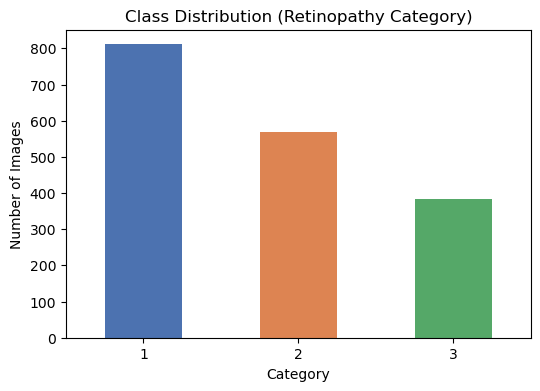

cat
1    811
2    569
3    384
Name: count, dtype: int64

Imbalance ratio (largest:smallest): 2.11


In [8]:
label_col = "cat"
counts = df[label_col].value_counts().sort_index()

plt.figure(figsize=(6, 4))
counts.plot(kind='bar', color=['#4C72B0', '#DD8452', '#55A868'])
plt.title("Class Distribution (Retinopathy Category)")
plt.xlabel("Category")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.show()

print(counts)
print(f"\nImbalance ratio (largest:smallest): {counts.max() / counts.min():.2f}")

In [ ]:
from PIL import Image

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for i, cls in enumerate(sorted(df[label_col].unique())):
    sample_file = df[df[label_col] == cls][filename_col].iloc[0]
    img = Image.open(os.path.join(images_dir, sample_file))
    axes[i].imshow(img)
    axes[i].set_title(f"Category {cls}\n{img.size}")
    axes[i].axis('off')
plt.tight_layout()
plt.show()

## 3. Build Data Generators (Train/Validation Split)

In [10]:
# flow_from_dataframe expects the label column as string for categorical mode
df['cat_str'] = df['cat'].astype(str)

img_size = (160, 160)
batch_size = 32

datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2,
    horizontal_flip=True,
    rotation_range=15,
    zoom_range=0.1,
    brightness_range=[0.9, 1.1]
)

train_gen = datagen.flow_from_dataframe(
    dataframe=df,
    directory=images_dir,
    x_col='file',
    y_col='cat_str',
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical',
    subset='training',
    seed=42
)

val_gen = datagen.flow_from_dataframe(
    dataframe=df,
    directory=images_dir,
    x_col='file',
    y_col='cat_str',
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical',
    subset='validation',
    seed=42
)

Found 1412 validated image filenames belonging to 3 classes.
Found 352 validated image filenames belonging to 3 classes.


In [11]:
print("Class indices:", train_gen.class_indices)
print("Training samples:", train_gen.samples)
print("Validation samples:", val_gen.samples)

Class indices: {'1': 0, '2': 1, '3': 2}
Training samples: 1412
Validation samples: 352


In [12]:
from sklearn.model_selection import train_test_split

df['cat_str'] = df['cat'].astype(str)

img_size = (160, 160)
batch_size = 32

train_df, val_df = train_test_split(
    df, test_size=0.2, stratify=df['cat'], random_state=42
)

print("Train shape:", train_df.shape)
print("Val shape:", val_df.shape)
print("\nTrain class distribution:\n", train_df['cat'].value_counts(normalize=True).sort_index())
print("\nVal class distribution:\n", val_df['cat'].value_counts(normalize=True).sort_index())

train_datagen = ImageDataGenerator(
    rescale=1./255,
    horizontal_flip=True,
    rotation_range=15,
    zoom_range=0.1,
    brightness_range=[0.9, 1.1]
)
val_datagen = ImageDataGenerator(rescale=1./255)

train_gen = train_datagen.flow_from_dataframe(
    dataframe=train_df, directory=images_dir, x_col='file', y_col='cat_str',
    target_size=img_size, batch_size=batch_size, class_mode='categorical',
    shuffle=True, seed=42
)

val_gen = val_datagen.flow_from_dataframe(
    dataframe=val_df, directory=images_dir, x_col='file', y_col='cat_str',
    target_size=img_size, batch_size=batch_size, class_mode='categorical',
    shuffle=False
)

Train shape: (1411, 4)
Val shape: (353, 4)

Train class distribution:
 cat
1    0.459957
2    0.322466
3    0.217576
Name: proportion, dtype: float64

Val class distribution:
 cat
1    0.458924
2    0.322946
3    0.218130
Name: proportion, dtype: float64
Found 1411 validated image filenames belonging to 3 classes.
Found 353 validated image filenames belonging to 3 classes.


## 4. Build the Model (Transfer Learning)

In [13]:
from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

In [14]:
from sklearn.utils.class_weight import compute_class_weight

classes = np.array(sorted(train_df['cat'].unique()))
weights = compute_class_weight(class_weight='balanced', classes=classes, y=train_df['cat'])
class_weights = {train_gen.class_indices[str(c)]: w for c, w in zip(classes, weights)}
print("Class weights:", class_weights)

Class weights: {0: np.float64(0.7247046738572163), 1: np.float64(1.0336996336996338), 2: np.float64(1.5320304017372421)}


In [15]:
base_model = MobileNetV2(input_shape=(160, 160, 3), include_top=False, weights='imagenet')
base_model.trainable = False

x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(64, activation='relu')(x)
output = Dense(3, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=output)
model.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                  ┃ Output Shape              ┃         Param # ┃ Connected to               ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)      │ (None, 160, 160, 3)       │               0 │ -                          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ Conv1 (Conv2D)                │ (None, 80, 80, 32)        │             864 │ input_layer[0][0]          │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ bn_Conv1 (BatchNormalization) │ (None, 80, 80, 32)        │             128 │ Conv1[0][0]                │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ Conv1_relu (ReLU)             │ (None, 80, 80, 32)        │               0 │ bn_Conv1[0][0]             │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ expanded_conv_depthwise       │ (None, 80, 80, 32)        │             288 │ Conv1_relu[0][0]           │
│ (DepthwiseConv2D)             │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ expanded_conv_depthwise_BN    │ (None, 80, 80, 32)        │             128 │ expanded_conv_depthwise[0… │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ expanded_conv_depthwise_relu  │ (None, 80, 80, 32)        │               0 │ expanded_conv_depthwise_B… │
│ (ReLU)                        │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ expanded_conv_project         │ (None, 80, 80, 16)        │             512 │ expanded_conv_depthwise_r… │
│ (Conv2D)                      │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ expanded_conv_project_BN      │ (None, 80, 80, 16)        │              64 │ expanded_conv_project[0][… │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block_1_expand (Conv2D)       │ (None, 80, 80, 96)        │           1,536 │ expanded_conv_project_BN[… │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block_1_expand_BN             │ (None, 80, 80, 96)        │             384 │ block_1_expand[0][0]       │
│ (BatchNormalization)          │                           │                 │                            │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block_1_expand_relu (ReLU)    │ (None, 80, 80, 96)        │               0 │ block_1_expand_BN[0][0]    │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block_1_pad (ZeroPadding2D)   │ (None, 81, 81, 96)        │               0 │ block_1_expand_relu[0][0]  │
├───────────────────────────────┼───────────────────────────┼─────────────────┼────────────────────────────┤
│ block_1_depthwise             │ (None, 40, 40, 96)        │             864 │ block_1_pad[0][0]          │
│ (DepthwiseConv2D)             │                           │               

 Total params: 2,340,163 (8.93 MB)

 Trainable params: 82,179 (321.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [16]:
history = model.fit(
    train_gen,
    validation_data=val_gen,
    epochs=15,
    class_weight=class_weights,
    callbacks=[early_stop]
)

Epoch 1/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 21s 408ms/step - accuracy: 0.6492 - loss: 0.8155 - val_accuracy: 0.6912 - val_loss: 0.6365
Epoch 2/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 17s 380ms/step - accuracy: 0.7690 - loss: 0.5764 - val_accuracy: 0.8017 - val_loss: 0.4797
Epoch 3/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 17s 383ms/step - accuracy: 0.8079 - loss: 0.4985 - val_accuracy: 0.8187 - val_loss: 0.4258
Epoch 4/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 18s 396ms/step - accuracy: 0.8058 - loss: 0.4942 - val_accuracy: 0.8329 - val_loss: 0.4272
Epoch 5/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 17s 382ms/step - accuracy: 0.8122 - loss: 0.5029 - val_accuracy: 0.8414 - val_loss: 0.4171
Epoch 6/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 17s 385ms/step - accuracy: 0.8257 - loss: 0.4611 - val_accuracy: 0.8499 - val_loss: 0.3993
Epoch 7/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 17s 382ms/step - accuracy: 0.8172 - loss: 0.4600 - val_accuracy: 0.8329 - val_loss: 0.4031
Epoch 8/15
45/45 ━━━━━━━━━━━━━━━━━━━━ 17s 379ms/step - accuracy: 0.8186 - loss: 0.4529 - val_accu

## 5. Training Curves & Evaluation

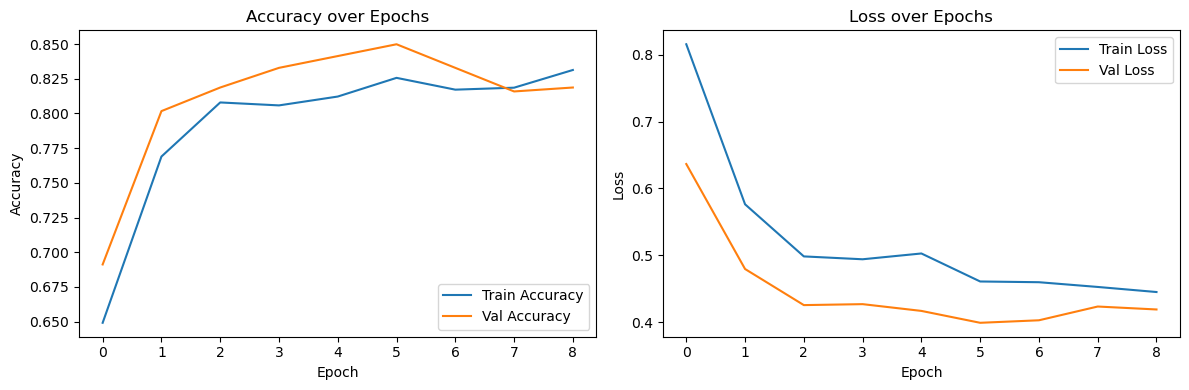

In [17]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('Accuracy over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('Loss over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [18]:
eval_gen = val_datagen.flow_from_dataframe(
    dataframe=val_df, directory=images_dir, x_col='file', y_col='cat_str',
    target_size=img_size, batch_size=batch_size, class_mode='categorical',
    shuffle=False
)

Found 353 validated image filenames belonging to 3 classes.


In [19]:
predictions = model.predict(eval_gen)
predicted_classes = np.argmax(predictions, axis=1)
true_classes = eval_gen.classes

print("Predictions shape:", predictions.shape)
print("Sample predicted:", predicted_classes[:10])
print("Sample true:     ", true_classes[:10])

12/12 ━━━━━━━━━━━━━━━━━━━━ 4s 252ms/step
Predictions shape: (353, 3)
Sample predicted: [0 0 2 2 0 2 0 2 1 0]
Sample true:      [0, 0, 1, 2, 0, 2, 0, 2, 2, 0]


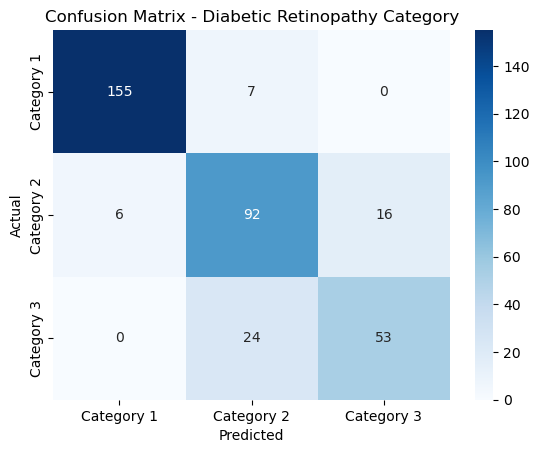

              precision    recall  f1-score   support

  Category 1       0.96      0.96      0.96       162
  Category 2       0.75      0.81      0.78       114
  Category 3       0.77      0.69      0.73        77

    accuracy                           0.85       353
   macro avg       0.83      0.82      0.82       353
weighted avg       0.85      0.85      0.85       353



In [20]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

class_labels = ['Category 1', 'Category 2', 'Category 3']

cm = confusion_matrix(true_classes, predicted_classes)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_labels, yticklabels=class_labels)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - Diabetic Retinopathy Category')
plt.show()

print(classification_report(true_classes, predicted_classes, target_names=class_labels))

In [21]:
model.save("retinopathy_model.keras")
print("Model saved as retinopathy_model.keras")

Model saved as retinopathy_model.keras


## 6. Model Interpretability with Grad-CAM

In [ ]:
import cv2

def make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=None):
    grad_model = tf.keras.models.Model(
        [model.inputs], [model.get_layer(last_conv_layer_name).output, model.output]
    )
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        if pred_index is None:
            pred_index = tf.argmax(predictions[0])
        class_channel = predictions[:, pred_index]

    grads = tape.gradient(class_channel, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]
    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy(), int(pred_index)

# MobileNetV2's last conv layer before pooling
last_conv_layer_name = "Conv_1"

def overlay_gradcam(img_path, model, last_conv_layer_name, img_size=(160,160)):
    img = Image.open(img_path).convert('RGB').resize(img_size)
    img_array = np.expand_dims(np.array(img) / 255.0, axis=0)

    heatmap, pred_class = make_gradcam_heatmap(img_array, model, last_conv_layer_name)
    heatmap = cv2.resize(heatmap, img_size)
    heatmap = np.uint8(255 * heatmap)
    heatmap_color = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)
    heatmap_color = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB)

    original = np.array(img)
    overlay = np.uint8(original * 0.6 + heatmap_color * 0.4)
    return original, overlay, pred_class

In [ ]:
# pick a few validation images across different true categories
sample_rows = val_df.groupby('cat').first().reset_index()

fig, axes = plt.subplots(len(sample_rows), 2, figsize=(8, 4*len(sample_rows)))
class_names = {0: 'Category 1', 1: 'Category 2', 2: 'Category 3'}

for i, row in sample_rows.iterrows():
    img_path = os.path.join(images_dir, row['file'])
    original, overlay, pred_class = overlay_gradcam(img_path, model, last_conv_layer_name)

    axes[i, 0].imshow(original)
    axes[i, 0].set_title(f"True: {row['cat_str']}")
    axes[i, 0].axis('off')

    axes[i, 1].imshow(overlay)
    axes[i, 1].set_title(f"Grad-CAM | Predicted: {class_names[pred_class]}")
    axes[i, 1].axis('off')

plt.tight_layout()
plt.show()

## 7. Interactive Prediction Demo

In [24]:
def predict_retinopathy(img_path, model, last_conv_layer_name="Conv_1", img_size=(160,160)):
    class_names = {0: 'Category 1 (Mild)', 1: 'Category 2 (Moderate)', 2: 'Category 3 (Severe)'}

    img = Image.open(img_path).convert('RGB').resize(img_size)
    img_array = np.expand_dims(np.array(img) / 255.0, axis=0)

    preds = model.predict(img_array, verbose=0)[0]
    pred_class = int(np.argmax(preds))
    confidence = float(preds[pred_class])

    heatmap, _ = make_gradcam_heatmap(img_array, model, last_conv_layer_name, pred_index=pred_class)
    heatmap_resized = cv2.resize(heatmap, img_size)
    heatmap_uint8 = np.uint8(255 * heatmap_resized)
    heatmap_color = cv2.applyColorMap(heatmap_uint8, cv2.COLORMAP_JET)
    heatmap_color = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB)
    overlay = np.uint8(np.array(img) * 0.6 + heatmap_color * 0.4)

    return class_names[pred_class], confidence, preds, np.array(img), overlay

In [ ]:
!pip install gradio

In [ ]:
import gradio as gr

def gradio_predict(image):
    image.save("temp_upload.jpg")
    label, confidence, all_probs, original, overlay = predict_retinopathy("temp_upload.jpg", model)

    prob_dict = {
        'Category 1 (Mild)': float(all_probs[0]),
        'Category 2 (Moderate)': float(all_probs[1]),
        'Category 3 (Severe)': float(all_probs[2])
    }
    return f"{label} ({confidence*100:.1f}% confidence)", prob_dict, overlay

demo = gr.Interface(
    fn=gradio_predict,
    inputs=gr.Image(type="pil", label="Upload a Retina Scan"),
    outputs=[
        gr.Text(label="Predicted Category"),
        gr.Label(label="Class Probabilities"),
        gr.Image(label="Grad-CAM Heatmap")
    ],
    title="Diabetic Retinopathy Severity Detector",
    description="Upload a retina fundus scan to predict diabetic retinopathy severity, with a heatmap showing which regions influenced the prediction."
)

demo.launch()

## Challenges Faced

1. **Flat file structure with CSV-based labels (not pre-sorted folders):** Unlike a typical classification setup where images live in per-class subfolders, all 1,764 images here sit in a single `images/` folder with labels in `data_all.csv`. This required using `flow_from_dataframe` instead of `flow_from_directory`, and careful filename-matching validation (confirmed 0 mismatches between CSV entries and actual image files) before any training could begin.

2. **Invalid train/validation split due to sorted filenames:** The initial approach used `ImageDataGenerator`'s built-in `validation_split`, which slices the dataset by row order rather than shuffling first. Because the CSV was sorted by category (`o_c1t...` filenames grouped by class), the resulting "validation set" contained only Category 1 images — silently invalidating every training-time validation metric (a misleadingly high 92.9% val_accuracy) and the first classification report (which showed 0% precision/recall for Categories 2 and 3). This was resolved by switching to a proper **stratified split** via `train_test_split(..., stratify=df['cat'])`, verified by comparing class proportions in both splits before retraining.

3. **Class imbalance (2.11:1 ratio):** Category 1 (811 images) outnumbers Category 3 (384 images) by over 2x. Addressed using `compute_class_weight('balanced')`, recalculated on the training split only, and passed into `model.fit()` to penalize misclassifying minority classes more heavily.

4. **Small dataset size (1,764 images total):** Far too small to train a CNN from scratch or fine-tune a large pretrained backbone without overfitting.

## Summary

- **Task:** Multi-class image classification — predicting diabetic retinopathy severity category (1, 2, or 3) from retina fundus images
- **Dataset:** 1,764 images with CSV-based labels, moderately imbalanced (811 / 569 / 384 across categories), stratified 80/20 split into training (1,411) and validation (353)
- **Approach:** Transfer learning using a frozen MobileNetV2 backbone (ImageNet-pretrained) with a custom classification head, trained with class weighting and data augmentation to handle the small, imbalanced dataset
- **Training:** Early stopping (patience=3, monitoring val_loss) halted training after 9 epochs, restoring the best-performing weights
- **Results:** 85% overall accuracy, 0.82 macro-average F1-score — strong performance on the majority class (Category 1: 0.96 precision, 0.96 recall) with reasonably balanced but comparatively weaker performance on minority classes (Category 2: 0.78 F1, Category 3: 0.73 F1)
- **Interpretability:** Grad-CAM heatmaps on a few validation images show the model focusing on localized regions of the retina rather than only the background or image edges. This is a qualitative sanity check only; it has not been validated against clinical annotations, and not every highlighted region lines up with visible lesions
- **Conclusion:** The model generalizes reasonably well given the limited dataset size, though performance on the minority classes (particularly Category 3 recall at 69%, meaning some severe cases are predicted as milder) is the primary limitation. In a clinical deployment context, this recall gap on the most severe category would need to be addressed — through more training data for underrepresented categories, or by tuning the decision threshold to favor recall over precision for high-severity cases — before the model could be trusted for real diagnostic use.